# 05 · Machine learning and model comparison

Real MetroPT-3 data. Run `python -m src.pipeline --csv data/raw/MetroPT3.csv` first to regenerate the analysis inputs. These notebooks also run directly on the aggregated outputs included in the delivery.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.config import ANALOG, DIGITAL
OUT = ROOT / 'data/processed'
x = pd.read_parquet(OUT / 'monitoring_5min.parquet')
events = pd.read_csv(ROOT / 'data/reference/failure_events.csv', parse_dates=['start','end'])
quality = json.loads((ROOT / 'reports/data_quality.json').read_text())
sns.set_theme(style='whitegrid', palette='colorblind')
pd.set_option('display.max_columns', 30)


## Feature and validation contract
Inputs: analog means, within-bin standard deviations, first differences, loaded fraction and panel–reservoir pressure gap. Training-median imputation and standardisation use February only. A 200-tree Isolation Forest and Ledoit–Wolf multivariate distance compete with statistical baselines. Fitted model parameters are in `models/detectors.joblib`.

0                       TP2
1                       TP3
2                        H1
3               DV_pressure
4                Reservoirs
5           Oil_temperature
6             Motor_current
7             load_fraction
8              pressure_gap
9                   TP2_std
10                  TP3_std
11                   H1_std
12          DV_pressure_std
13           Reservoirs_std
14      Oil_temperature_std
15        Motor_current_std
16                TP2_delta
17                TP3_delta
18                 H1_delta
19        DV_pressure_delta
20         Reservoirs_delta
21    Oil_temperature_delta
22      Motor_current_delta
Name: Model inputs, dtype: object

,model,proxy_precision,proxy_recall,proxy_f1,tp,fp_proxy,fn,tn_proxy,test_bins,alert_bins,alert_rate,alerts_outside_documented_windows,outside_alert_episodes,outside_episodes_per_observed_day,event_recall
0,zscore,0.598318,0.937183,0.730359,925,621,62,32006,33614,1546,0.045993,621,20,0.176541,0.75
1,rolling_z,0.000000,0.000000,0.000000,0,0,987,32627,33614,0,0.000000,0,0,0.000000,0.00
2,cusum,0.606697,0.936170,0.736255,924,599,63,32028,33614,1523,0.045309,599,14,0.123579,0.75
3,isolation_forest,0.045455,0.001013,0.001982,1,21,986,32606,33614,22,0.000654,21,20,0.176541,0.25
4,mahalanobis,0.598706,0.937183,0.730648,925,620,62,32007,33614,1545,0.045963,620,20,0.176541,0.75
5,threshold,0.597931,0.937183,0.730071,925,622,62,32005,33614,1547,0.046022,622,21,0.185368,0.75


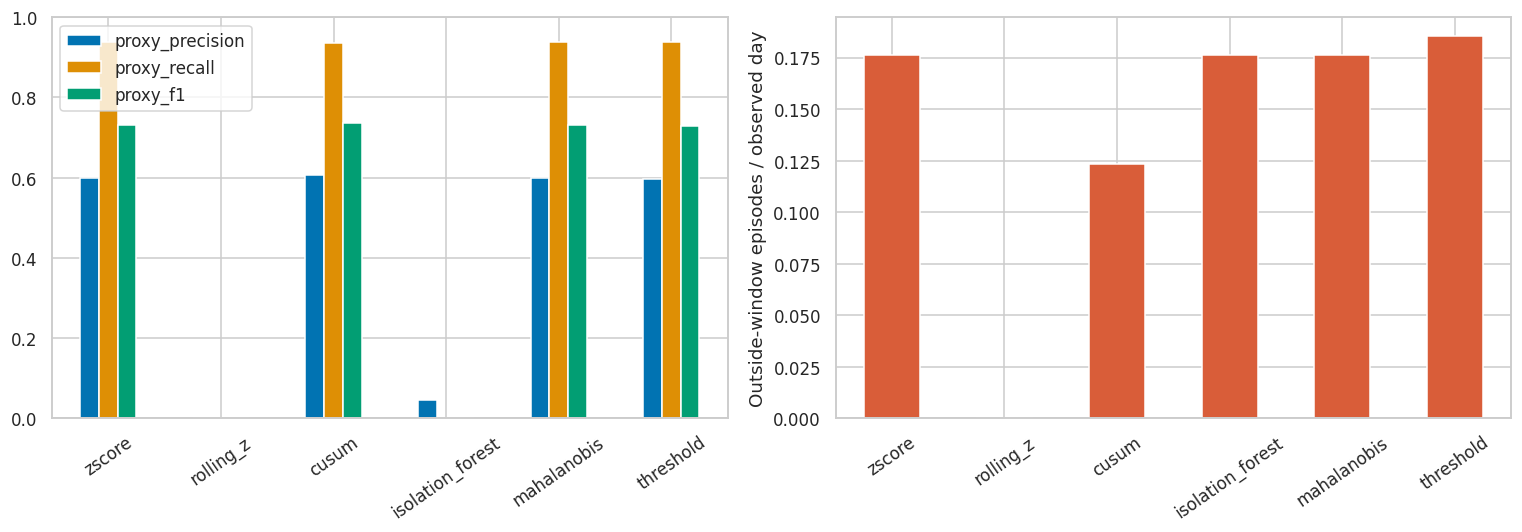

In [2]:
from src.feature_engineering import model_columns
display(pd.Series(model_columns(),name='Model inputs'))
metrics=pd.read_csv(OUT/'model_comparison.csv')
display(metrics)
fig,axs=plt.subplots(1,2,figsize=(14,5))
metrics.set_index('model')[['proxy_precision','proxy_recall','proxy_f1']].plot.bar(ax=axs[0]); axs[0].set_ylim(0,1)
metrics.set_index('model').outside_episodes_per_observed_day.plot.bar(ax=axs[1],color='#d95d39'); axs[1].set_ylabel('Outside-window episodes / observed day')
for ax in axs: ax.tick_params(axis='x',rotation=35); ax.set_xlabel('')
plt.tight_layout(); plt.show()


## Confusion matrices
Rows are reported-window proxy labels; columns are alerts. A false-positive cell means outside a documented interval, not a confirmed false alarm. Poor-quality intervals are excluded.

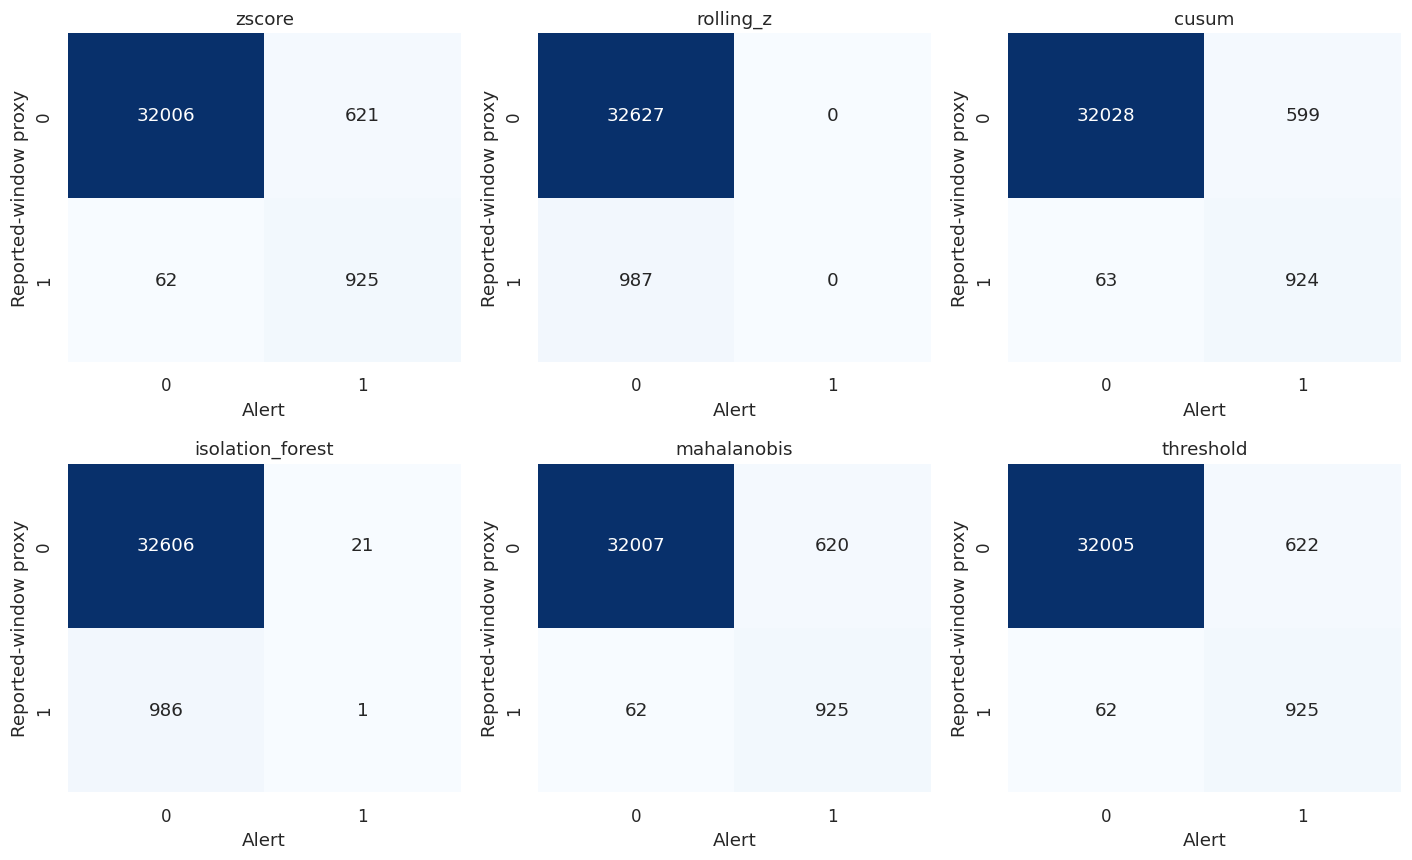

In [3]:
from sklearn.metrics import confusion_matrix
fig,axs=plt.subplots(2,3,figsize=(13,8))
mask=x.split.eq('test') & x.quality_eligible
for ax,model in zip(axs.flat,metrics.model):
    cm=confusion_matrix(x.loc[mask,'event_window'],x.loc[mask,model+'_alert'],labels=[False,True])
    sns.heatmap(cm,annot=True,fmt='d',cbar=False,ax=ax,cmap='Blues')
    ax.set(title=model,xlabel='Alert',ylabel='Reported-window proxy')
plt.tight_layout(); plt.show()


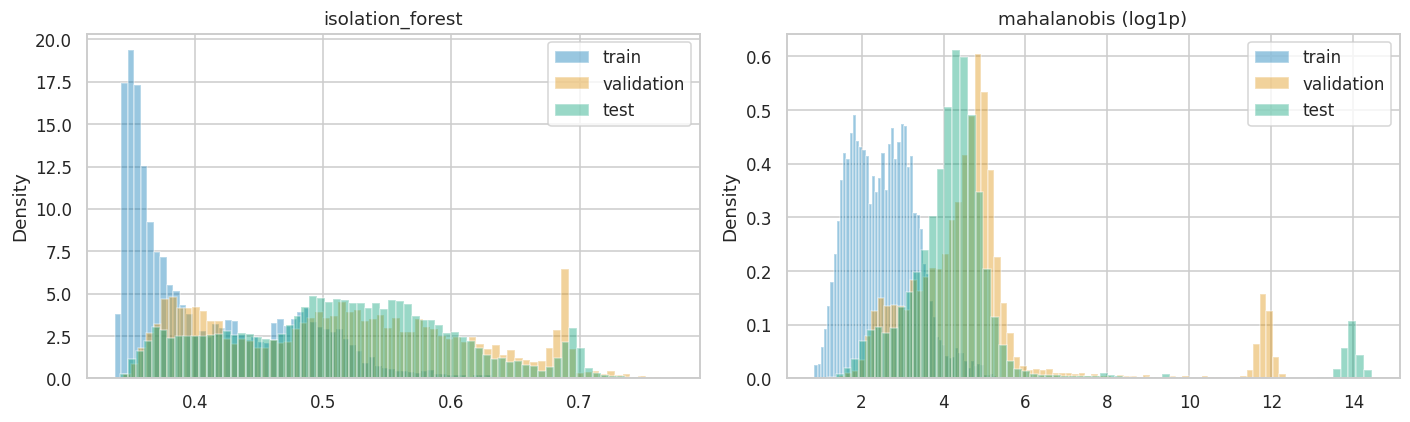

In [4]:
# Scores by split reveal distribution shift and explain calibration behaviour.
fig,axs=plt.subplots(1,2,figsize=(13,4))
for ax,model in zip(axs,['isolation_forest','mahalanobis']):
    for split in ['train','validation','test']:
        values=x.loc[x.split.eq(split)&x.quality_eligible,model+'_score'].dropna()
        if model=='mahalanobis': values=np.log1p(values)
        ax.hist(values,bins=70,density=True,alpha=.4,label=split)
    ax.set(title=model+(' (log1p)' if model=='mahalanobis' else ''),ylabel='Density'); ax.legend()
plt.tight_layout(); plt.show()


In [5]:
monthly=x.loc[mask].resample('MS').agg(eligible_bins=('quality_eligible','sum'),event_bins=('event_window','sum'),IF_alert_bins=('isolation_forest_alert','sum'),CUSUM_alert_bins=('cusum_alert','sum'))
display(monthly)
result=metrics.sort_values('proxy_f1',ascending=False).iloc[0]
display(Markdown(f'Highest observed test proxy F1: **{result.model}**, **{result.proxy_f1:.3f}**. This comparison does not establish deployment readiness.'))


,eligible_bins,event_bins,IF_alert_bins,CUSUM_alert_bins
timestamp,,,,
2020-04-01,6188,283,9,450
2020-05-01,6597,79,10,479
2020-06-01,6376,571,2,594
2020-07-01,7177,54,0,0
2020-08-01,7260,0,1,0
2020-09-01,16,0,0,0


Highest observed test proxy F1: **cusum**, **0.736**. This comparison does not establish deployment readiness.

## Model limitations and next experiment
Retain the full comparison, including weak models. Isolation Forest need not be best for persistent compressor faults; a global multivariate score may be dominated by operating-state or seasonal changes. Test event labels must not be used to retune contamination, feature selection or persistence. A next experiment could use load-state-specific references and an agreed alert budget, evaluated on new equipment or a later period. Only four recorded events are insufficient for a reliable deployment claim.